# ECS 174 Computer Vision Final Project Code

### Adam Hetherwick's code

November 2026

Microsoft COCO (common objects in context) dataset using a subset with 10 animal classes with bounding box and label annotations

Goal: Train a multi head model to best predict bounding box region (MSE loss) and animal classification (cross entropy loss).

To implement:

1. Subset data
2. Example images, EDA
3. Create train test split (important for pretrained model)
4. Implement models (YOLOv8, CNN? R-CNN?)
5. Evaluate results (runtime, mean Average Precision)
6. Compare results to COCO DPM (deformable parts model)?

### Load dataset

#### Google Colab version

In [21]:
!pip install -q ultralytics fiftyone urllib

ERROR: Ignored the following versions that require a different python version: 0.6.0 Requires-Python >=3.5,<3.9; 0.6.0.1 Requires-Python >=3.5,<3.9; 0.6.1 Requires-Python >=3.5,<3.9; 0.6.1.1 Requires-Python >=3.5,<3.9; 0.6.2 Requires-Python >=3.5,<3.9; 0.6.3 Requires-Python >=3.5,<3.9; 0.6.4 Requires-Python >=3.5,<3.9; 0.6.5 Requires-Python >=3.5,<3.9; 0.6.5.1 Requires-Python >=3.5,<3.9; 0.6.5.2 Requires-Python >=3.5,<3.9; 0.6.6 Requires-Python >=3.5,<3.9; 0.7.0 Requires-Python >=3.5,<3.9; 8.0.10 Requires-Python >=3.7,<=3.11; 8.0.11 Requires-Python >=3.7,<=3.11; 8.0.12 Requires-Python >=3.7,<=3.11; 8.0.13 Requires-Python >=3.7,<=3.11; 8.0.14 Requires-Python >=3.7,<=3.11; 8.0.15 Requires-Python >=3.7,<=3.11; 8.0.16 Requires-Python >=3.7,<=3.11; 8.0.17 Requires-Python >=3.7,<=3.11; 8.0.18 Requires-Python >=3.7,<=3.11; 8.0.19 Requires-Python >=3.7,<=3.11; 8.0.20 Requires-Python >=3.7,<=3.11; 8.0.21 Requires-Python >=3.7,<=3.11; 8.0.22 Requires-Python >=3.7,<=3.11; 8.0.23 Requires-Python >

In [2]:
# 2. Mount Google Drive
from google.colab import drive
drive.mount('/content/drive')
RUNS_DIR = '/content/drive/MyDrive/ECS_174_Final_Project/model_checkpoints'

Mounted at /content/drive


In [3]:
import os, random, zipfile, urllib.request
from concurrent.futures import ThreadPoolExecutor
import requests
from tqdm import tqdm
from pycocotools.coco import COCO

coco_data_loc = '/content/coco_data'
os.makedirs(coco_data_loc, exist_ok=True)

# 1) Annotations (~250 MB), skipped if already there
if not os.path.exists(f'{coco_data_loc}/annotations/instances_val2017.json'):
    url = 'http://images.cocodataset.org/annotations/annotations_trainval2017.zip'
    zp = f'{coco_data_loc}/annotations_trainval2017.zip'
    urllib.request.urlretrieve(url, zp)
    with zipfile.ZipFile(zp) as z:
        z.extractall(coco_data_loc)         # creates coco_data/annotations/
    os.remove(zp)

def split_dir(split):
    return f'{coco_data_loc}/data/{split}2017'

def download_animal_images(split, max_images=None, seed=42, max_workers=16):
    out_dir = split_dir(split)
    marker = os.path.join(out_dir, '.download_complete')
    if os.path.exists(marker):
        print(f'{split}: already downloaded, skipping')
        return

    coco = COCO(f'{coco_data_loc}/annotations/instances_{split}2017.json')
    animal_ids = coco.getCatIds(supNms=['animal'])
    ids = set()
    for cid in animal_ids:
        ids.update(coco.getImgIds(catIds=[cid]))
    ids = sorted(ids)
    if max_images and len(ids) > max_images:            # random subset, reproducible
        random.Random(seed).shuffle(ids)
        ids = ids[:max_images]
    imgs = coco.loadImgs(ids)
    print(f'{split}: downloading {len(imgs)} animal images')

    os.makedirs(out_dir, exist_ok=True)

    def fetch(img):
        path = os.path.join(out_dir, img['file_name'])
        if os.path.exists(path):
            return
        r = requests.get(img['coco_url'], timeout=30)
        r.raise_for_status()
        with open(path, 'wb') as f:
            f.write(r.content)

    with ThreadPoolExecutor(max_workers) as ex:
        list(tqdm(ex.map(fetch, imgs), total=len(imgs)))

    open(marker, 'w').close()
    print(f'{split}: done')

In [4]:
download_animal_images('val')                      # all ~1,000 animal val images

loading annotations into memory...
Done (t=0.56s)
creating index...
index created!
val: downloading 1016 animal images


100%|██████████| 1016/1016 [00:31<00:00, 32.64it/s]

val: done


In [5]:
download_animal_images('train', max_images=8000)   # only the 8,000-image subset

loading annotations into memory...
Done (t=18.17s)
creating index...
index created!
train: downloading 8000 animal images


100%|██████████| 8000/8000 [04:23<00:00, 30.41it/s]


train: done


#### Desktop version

In [ ]:
coco_data_loc = "C:/Users/cheif/OneDrive/Documents/coco_data"

In [ ]:
import os
from concurrent.futures import ThreadPoolExecutor
import requests
from tqdm import tqdm
from pycocotools.coco import COCO

os.chdir("C:/Users/cheif/OneDrive/Documents/GitHub/ECS_174_Final_Project")

coco_data_loc = "C:/Users/cheif/OneDrive/Documents/coco_data"

def split_dir(split):
    return f'{coco_data_loc}/data/{split}2017'            # single source of truth for the path

def download_animal_images(split, max_workers=16):
    out_dir = split_dir(split)
    marker = os.path.join(out_dir, '.download_complete')

    if os.path.exists(marker):                            # only checks the split being requested
        print(f'{split}: already downloaded, skipping')
        return

    coco = COCO(f'{coco_data_loc}/annotations/instances_{split}2017.json')

    animal_ids = coco.getCatIds(supNms=['animal'])        # the 10 official animal classes
    img_ids = set()
    for cid in animal_ids:
        img_ids.update(coco.getImgIds(catIds=[cid]))
    imgs = coco.loadImgs(list(img_ids))
    print(f'{split}: {len(imgs)} animal images')

    os.makedirs(out_dir, exist_ok=True)

    def fetch(img):
        path = os.path.join(out_dir, img['file_name'])
        if os.path.exists(path):                          # skip files you already have
            return
        r = requests.get(img['coco_url'], timeout=30)
        r.raise_for_status()
        with open(path, 'wb') as f:
            f.write(r.content)

    with ThreadPoolExecutor(max_workers) as ex:
        list(tqdm(ex.map(fetch, imgs), total=len(imgs)))  # progress bar; errors still raise here

    open(marker, 'w').close()                             # only reached if every download succeeded
    print(f'{split}: done')

for split in ['val', 'train']:
    download_animal_images(split)

val: already downloaded, skipping
train: already downloaded, skipping


In [ ]:
download_animal_images('val')     # ~1,000 images, quick

val: already downloaded, skipping


WARNING: Below cell may take 5-30 minutes to run depending on compute power.

Last run: ~14 min

In [ ]:
download_animal_images('train')   # ~24,000 images, takes a while

train: already downloaded, skipping


Note: We use the COCO:validation set as our test set because COCO:test labels are private.

### Example Image Viewing (train, test)

In [ ]:
import random
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from PIL import Image

def split_dir(split):
    return f'{coco_data_loc}/data/{split}2017'      # same helper as the download function

def load_split(split):
    coco = COCO(f'{coco_data_loc}/annotations/instances_{split}2017.json')

    animal_ids = coco.getCatIds(supNms=['animal'])
    img_ids = set()
    for cid in animal_ids:
        img_ids.update(coco.getImgIds(catIds=[cid]))
    # keep only images that are actually downloaded
    img_ids = [i for i in img_ids
               if os.path.exists(f"{split_dir(split)}/{coco.imgs[i]['file_name']}")]
    print(f'{split}: {len(img_ids)} downloaded animal images')   # quick sanity check
    return coco, animal_ids, img_ids

def draw(ax, coco, animal_ids, split, img_id):
    info = coco.imgs[img_id]
    img = Image.open(f"{split_dir(split)}/{info['file_name']}").convert('RGB')
    ax.imshow(img)
    anns = coco.loadAnns(coco.getAnnIds(imgIds=img_id, catIds=animal_ids, iscrowd=None))
    for a in anns:
        x, y, w, h = a['bbox']
        ax.add_patch(patches.Rectangle((x, y), w, h, fill=False, edgecolor='lime', linewidth=2))
        ax.text(x, y - 3, coco.cats[a['category_id']]['name'],
                color='black', fontsize=9, backgroundcolor='lime')
    ax.set_title(f"{split}: {info['file_name']}", fontsize=9)
    ax.axis('off')

In [ ]:
splits = {s: load_split(s) for s in ['train', 'val']}

loading annotations into memory...
Done (t=14.89s)
creating index...
index created!
train: 23989 downloaded animal images
loading annotations into memory...
Done (t=0.48s)
creating index...
index created!
val: 1016 downloaded animal images


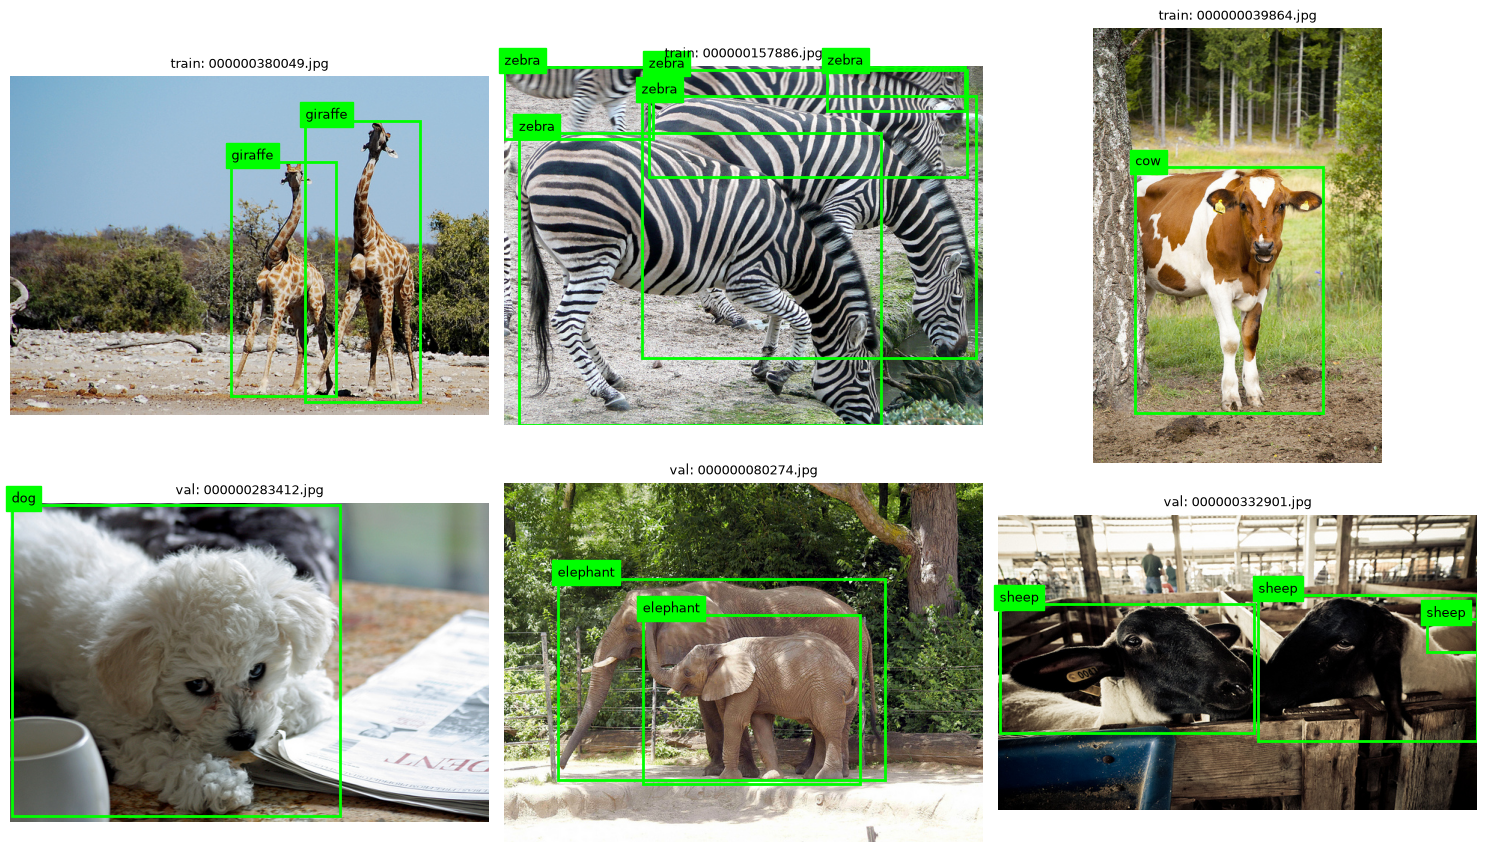

In [ ]:
fig, axes = plt.subplots(2, 3, figsize=(15, 9))
for row, split in enumerate(['train', 'val']):               # row 0 = train, row 1 = validation
    coco, animal_ids, img_ids = splits[split]
    for ax, img_id in zip(axes[row], random.sample(img_ids, 3)):
        draw(ax, coco, animal_ids, split, img_id)
plt.tight_layout()
plt.show()

### Exploratory Data Analysis

In [ ]:
import pandas as pd

def class_frequency_tables(splits):
    tables = {}
    for count in ['instances', 'images']:
        raw = pd.DataFrame({
            'train': class_counts(*splits['train'], count=count),
            'val':   class_counts(*splits['val'],   count=count),
        }).sort_values('train', ascending=False)

        pct = (raw / raw.sum() * 100).round(2)          # share of each split

        tables[f'{count}_raw'] = raw
        tables[f'{count}_pct'] = pct
    return tables

tables = class_frequency_tables(splits)

for name, t in tables.items():
    print(f'\n=== {name} ===')
    print(t)


=== instances_raw ===
          train  val
bird      10542  427
sheep      9223  354
cow        8014  372
horse      6567  272
dog        5500  218
elephant   5484  252
zebra      5269  266
giraffe    5128  232
cat        4766  202
bear       1294   71

=== instances_pct ===
          train    val
bird      17.06  16.02
sheep     14.93  13.28
cow       12.97  13.95
horse     10.63  10.20
dog        8.90   8.18
elephant   8.88   9.45
zebra      8.53   9.98
giraffe    8.30   8.70
cat        7.71   7.58
bear       2.09   2.66

=== images_raw ===
          train  val
dog        4385  177
cat        4114  184
bird       3237  125
horse      2941  128
giraffe    2546  101
elephant   2143   89
cow        1968   87
zebra      1916   85
sheep      1529   65
bear        960   49

=== images_pct ===
          train    val
dog       17.04  16.24
cat       15.98  16.88
bird      12.58  11.47
horse     11.43  11.74
giraffe    9.89   9.27
elephant   8.33   8.17
cow        7.65   7.98
zebra      7.44

In [ ]:
import numpy as np
import pandas as pd

def box_size_table(coco, animal_ids, img_ids):
    """Rows = classes, columns = % of boxes that are small / medium / large."""
    anns = coco.loadAnns(coco.getAnnIds(imgIds=img_ids, catIds=animal_ids, iscrowd=False))
    df = pd.DataFrame(anns)[['category_id', 'area']]
    df['class'] = df['category_id'].map(lambda c: coco.cats[c]['name'])
    df['size'] = pd.cut(df['area'],
                        bins=[0, 32**2, 96**2, np.inf],
                        labels=['small', 'medium', 'large'])

    table = pd.crosstab(df['class'], df['size'], normalize='index') * 100
    return table.round(1)

train_sizes = box_size_table(*splits['train'])
val_sizes   = box_size_table(*splits['val'])

print('Train: % of boxes by size')
print(train_sizes)
print('\nVal: % of boxes by size')
print(val_sizes)

Train: % of boxes by size
size      small  medium  large
class                         
bear        2.9    21.9   75.3
bird       65.0    22.5   12.5
cat         2.6    19.2   78.1
cow        39.6    36.6   23.8
dog        12.1    31.8   56.1
elephant   13.6    34.2   52.3
giraffe     8.3    34.4   57.3
horse      22.3    36.6   41.2
sheep      45.0    37.9   17.2
zebra      14.0    38.4   47.6

Val: % of boxes by size
size      small  medium  large
class                         
bear        7.0    18.3   74.6
bird       68.9    19.9   11.2
cat         2.0    18.3   79.7
cow        41.9    33.1   25.0
dog         8.7    28.4   62.8
elephant    6.7    38.1   55.2
giraffe    11.2    41.8   47.0
horse      21.7    36.0   42.3
sheep      30.5    44.9   24.6
zebra      18.0    35.7   46.2


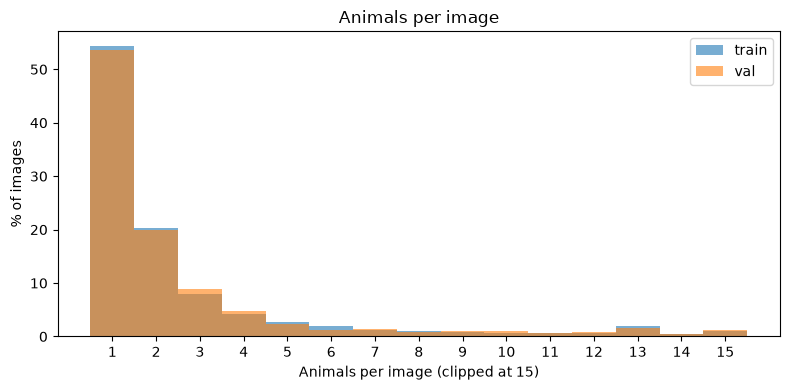

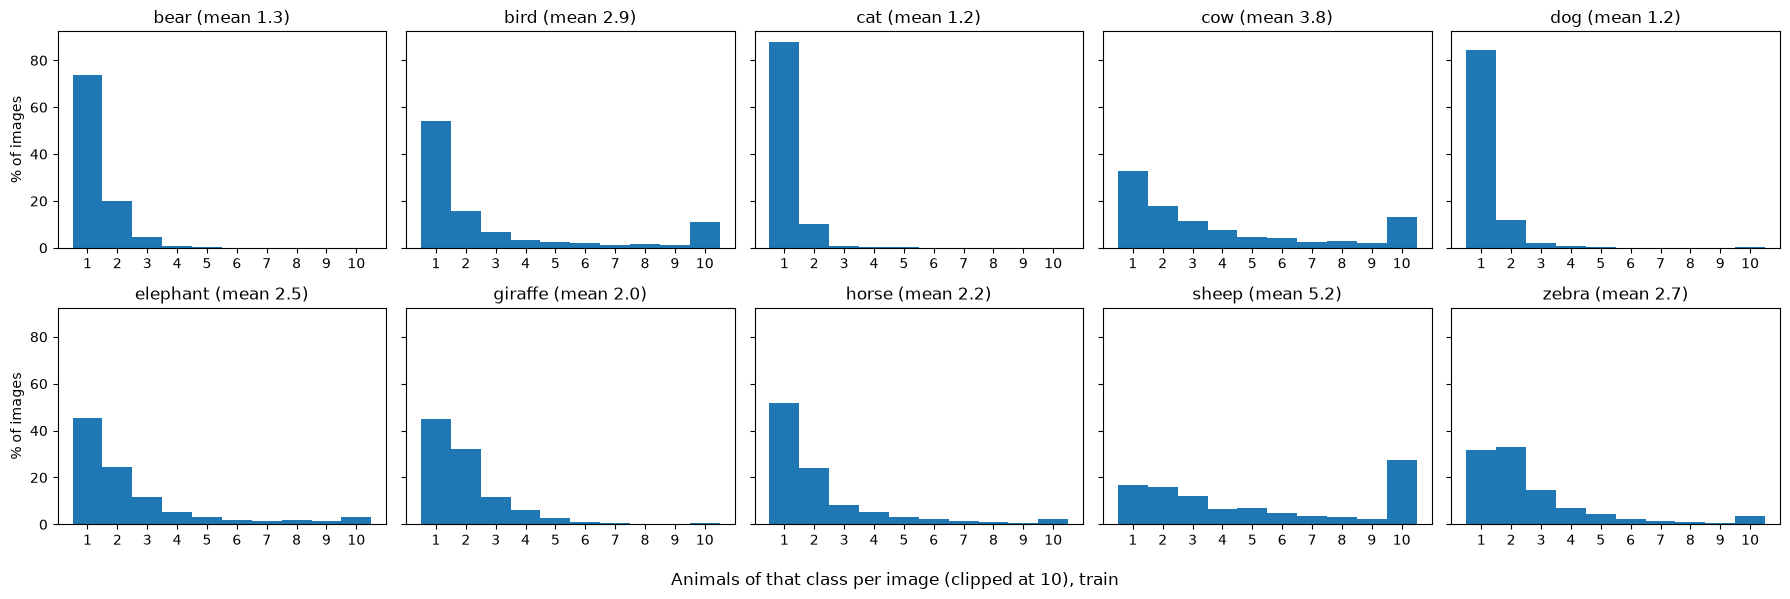

        images  mean  median  % with 1 animal  % with >=5   max
train  23989.0  2.58     1.0            54.39       13.12  35.0
val     1016.0  2.62     1.0            53.64       12.60  25.0

Train, animals of the class per image containing that class
          mean  median  max
class                      
sheep     6.03     4.0   23
cow       4.07     2.0   18
bird      3.26     1.0   27
zebra     2.75     2.0   14
elephant  2.56     2.0   14
horse     2.23     1.0   17
giraffe   2.01     2.0   13
bear      1.35     1.0   10
dog       1.25     1.0   19
cat       1.16     1.0   16


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

def animals_per_image(coco, animal_ids, img_ids):
    """One row per (image, class): how many non-crowd boxes of that class are in the image."""
    anns = coco.loadAnns(coco.getAnnIds(imgIds=img_ids, catIds=animal_ids, iscrowd=False))
    df = pd.DataFrame(anns)[['image_id', 'category_id']]
    df['class'] = df['category_id'].map(lambda c: coco.cats[c]['name'])
    return df

dfs = {s: animals_per_image(*splits[s]) for s in ['train', 'val']}

# ---------- 1. Overall: total animals per image ----------
CLIP = 15                                            # lump everything >= 15 into the last bin
fig, ax = plt.subplots(figsize=(8, 4))
bins = np.arange(1, CLIP + 2) - 0.5
for s, df in dfs.items():
    per_img = df.groupby('image_id').size().clip(upper=CLIP)
    ax.hist(per_img, bins=bins, weights=np.ones(len(per_img)) / len(per_img) * 100,
            alpha=0.6, label=s)
ax.set_xlabel(f'Animals per image (clipped at {CLIP})')
ax.set_ylabel('% of images')
ax.set_title('Animals per image')
ax.set_xticks(range(1, CLIP + 1))
ax.legend()
plt.tight_layout()
plt.show()

# ---------- 2. Per class: animals of that class per image ----------
classes = sorted(dfs['train']['class'].unique())
CLIP_C = 10
fig, axes = plt.subplots(2, 5, figsize=(18, 6), sharey=True)
for ax, cls in zip(axes.ravel(), classes):
    counts = (dfs['train'][dfs['train']['class'] == cls]
              .groupby('image_id').size().clip(upper=CLIP_C))
    ax.hist(counts, bins=np.arange(1, CLIP_C + 2) - 0.5,
            weights=np.ones(len(counts)) / len(counts) * 100)
    ax.set_title(f'{cls} (mean {counts.mean():.1f})')
    ax.set_xticks(range(1, CLIP_C + 1))
axes[0, 0].set_ylabel('% of images'); axes[1, 0].set_ylabel('% of images')
fig.supxlabel(f'Animals of that class per image (clipped at {CLIP_C}), train')
plt.tight_layout()
plt.show()

# ---------- 3. Summary table ----------
rows = {}
for s, df in dfs.items():
    per_img = df.groupby('image_id').size()
    rows[s] = {'images': len(per_img),
               'mean': per_img.mean(),
               'median': per_img.median(),
               '% with 1 animal': (per_img == 1).mean() * 100,
               '% with >=5': (per_img >= 5).mean() * 100,
               'max': per_img.max()}
print(pd.DataFrame(rows).T.round(2))

per_class = (dfs['train'].groupby(['class', 'image_id']).size()
             .groupby('class').agg(mean='mean', median='median', max='max').round(2))
print('\nTrain, animals of the class per image containing that class')
print(per_class.sort_values('mean', ascending=False))

### Modeling

#### YOLO26

In [7]:
coco_data_loc = "/content/coco_data"
YOLO_DIR = "/content/yolo_animals"

In [17]:
!python /content/build_yolo_dataset.py

loading annotations into memory...
Done (t=13.37s)
creating index...
index created!
loading annotations into memory...
Done (t=1.19s)
creating index...
index created!
train: 8000 | dev: 508 | test: 508 images
classes: ['bird', 'cat', 'dog', 'horse', 'sheep', 'cow', 'elephant', 'bear', 'zebra', 'giraffe']
wrote /content/yolo_animals/dataset.yaml


In [18]:
import shutil
shutil.make_archive('/content/drive/MyDrive/ECS_174_Final_Project/yolo_animals', 'zip', '/content/yolo_animals')

'/content/drive/MyDrive/ECS_174_Final_Project/yolo_animals.zip'

In [19]:
!unzip -q /content/drive/MyDrive/ECS_174_Final_Project/yolo_animals.zip -d /content/yolo_animals

replace /content/yolo_animals/dataset.yaml? [y]es, [n]o, [A]ll, [N]one, [r]ename: 

In [23]:
!pip install ultralytics

  Using cached ultralytics-8.4.218-py3-none-any.whl.metadata (47 kB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.5/1.5 MB 13.9 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3/3 [ultralytics]


In [27]:
from ultralytics import YOLO

YOLO_DIR = "/content/yolo_animals"
RUNS_DIR = "/content/drive/MyDrive/ECS_174_Final_Project/yolo_runs"
DATA = f"{YOLO_DIR}/dataset.yaml"
DEVICE = 0

In [28]:
def main():
    # ---- 1) Smoke test: 1 epoch on 10% of the data, just to confirm everything runs ----
    # YOLO("yolo26s.pt").train(data=DATA, epochs=1, fraction=0.1, imgsz=640, batch=16,
    #                          project=RUNS_DIR, name="smoke_test", device=DEVICE)

    # ---- 2) Real run: pretrained, fine-tune the whole network ----
    model = YOLO("yolo26s.pt")   # 's' size; check the Ultralytics docs for exact weight names
    results = model.train(
        data=DATA,
        epochs=30,
        patience=10,             # stop early if dev mAP stops improving
        imgsz=640,
        batch=32,                # lower to 16 if you run out of GPU memory
        seed=0,                  # keep fixed across experiments
        project=RUNS_DIR,
        name="yolo26s_pretrained_finetune",
        device=DEVICE,
        # freeze=10,             # ablation: freeze the first 10 layers (backbone)
        # imgsz=960,             # ablation: larger input for small animals like birds
    )

    # ---- 3) Final evaluation on the held-out TEST split (run once, at the end) ----
    best = YOLO(f"{results.save_dir}/weights/best.pt")
    m = best.val(data=DATA, split="test")
    print("test mAP50   :", round(float(m.box.map50), 4))
    print("test mAP50-95:", round(float(m.box.map), 4))
    for i, ap in enumerate(m.box.maps):
        print(f"  {best.names[i]:10s} mAP50-95 = {ap:.3f}")

In [29]:
if __name__ == "__main__":       # required on Windows (dataloader workers re-import this file)
    main()

Ultralytics 8.4.218 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=32, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/yolo_animals/dataset.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=30, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=None, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo26s.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=yolo26s_pretrained_finetune, nbs=64, nms=None, opset=